# Machine Learning - Assignment 2

## Predicting term deposit subscription (UCI Bank Marketing)

**Name:** MALLIPEDDI DATTA SAI  
**BITS ID:** 2026CT05139

The goal is to predict whether a client of a Portuguese bank will subscribe to a term deposit after a
telemarketing call. Five classification models are trained on the same data and compared on Accuracy,
AUC, Precision, Recall, F1 and MCC.

In [2]:
import warnings
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, confusion_matrix, roc_curve)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
TARGET = "y"

# this notebook sits in model/, all other paths are taken from the project root
ROOT = Path.cwd().parent if Path.cwd().name == "model" else Path.cwd()
DATA_PATH = ROOT / "data" / "bank-additional-full.csv"
RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)
print("Project root:", ROOT.name)

Project root: bank-marketing-classification


## 1. Dataset

**Source:** UCI Machine Learning Repository - Bank Marketing (`bank-additional-full.csv`),
https://archive.ics.uci.edu/dataset/222/bank+marketing

**Why this dataset:** it comfortably meets the size requirement (41,188 rows, 20 features), it mixes
numeric and categorical features so encoding and scaling both matter, it has missing values recorded as
`unknown`, it has a few duplicate rows, and the target is clearly imbalanced. That makes it a good case
for comparing metrics beyond accuracy.

**Target variable:** `y` - did the client subscribe to a term deposit (`yes` / `no`). Binary classification.

In [4]:
df = pd.read_csv(DATA_PATH, sep=";")
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [5]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(exclude="number").columns.drop(TARGET).tolist()

print(f"Features: {df.shape[1] - 1}  (numeric: {len(numeric_cols)}, categorical: {len(categorical_cols)})")
print("\nNumeric    :", numeric_cols)
print("Categorical:", categorical_cols)
print("\nCategories per categorical feature:")
print(df[categorical_cols].nunique().to_string())

Features: 20  (numeric: 10, categorical: 10)

Numeric    : ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

Categories per categorical feature:
job            12
marital         4
education       8
default         3
housing         3
loan            3
contact         2
month          10
day_of_week     5
poutcome        3


In [6]:
df[numeric_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00
duration,41188.0,258.29,259.28,0.00,102.00,180.00,319.00,4918.00
campaign,41188.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00
pdays,41188.0,962.48,186.91,0.00,999.00,999.00,999.00,999.00
previous,41188.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00
emp.var.rate,41188.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,41188.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,41188.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,41188.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04
nr.employed,41188.0,5167.04,72.25,4963.60,5099.10,5191.00,5228.10,5228.10


### 1.1 Missing values

`isna()` reports nothing because the file codes missing answers as the string `unknown`.
I convert those to `NaN` so they are counted and handled as missing values.

In [8]:
print("NaN cells before recoding:", int(df.isna().sum().sum()))

df = df.replace("unknown", np.nan)

missing = pd.DataFrame({"missing": df.isna().sum(),
                        "percent": (df.isna().mean() * 100).round(2)})
missing = missing[missing["missing"] > 0].sort_values("missing", ascending=False)
print("NaN cells after recoding :", int(df.isna().sum().sum()))
missing

NaN cells before recoding: 0
NaN cells after recoding : 12718


,missing,percent
default,8597,20.87
education,1731,4.20
housing,990,2.40
loan,990,2.40
job,330,0.80
marital,80,0.19


Five columns have under 5% missing, so filling them with the most frequent category is reasonable.
`default` is different: about 21% is missing and almost nobody answers `yes`, so "not disclosed" looks
like information in itself. I keep it as its own category instead of imputing it away.
The imputers are part of the pipeline in section 3, so they are fitted on the training split only.

### 1.2 Duplicates

In [11]:
n_dup = int(df.duplicated().sum())
print("Duplicate rows:", n_dup)

df = df.drop_duplicates().reset_index(drop=True)
print("Shape after dropping duplicates:", df.shape)

Duplicate rows: 12
Shape after dropping duplicates: (41176, 21)


### 1.3 Class distribution

     count  percent
y                  
no   36537    88.73
yes   4639    11.27

Imbalance ratio (no : yes) = 7.88 : 1
Accuracy of always predicting 'no' = 88.73%


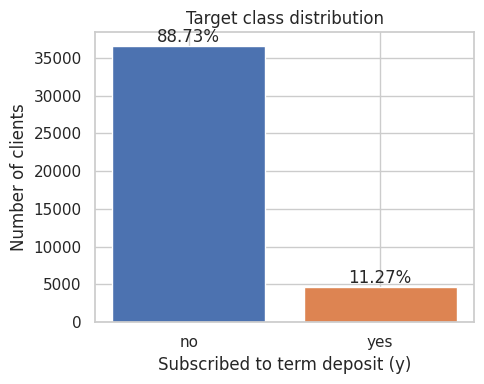

In [13]:
class_counts = df[TARGET].value_counts()
class_pct = (class_counts / len(df) * 100).round(2)
print(pd.DataFrame({"count": class_counts, "percent": class_pct}))
print(f"\nImbalance ratio (no : yes) = {class_counts['no'] / class_counts['yes']:.2f} : 1")
print(f"Accuracy of always predicting 'no' = {class_pct['no']:.2f}%")

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(class_counts.index, class_counts.values, color=["#4c72b0", "#dd8452"])
for bar, pct in zip(bars, class_pct.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{pct}%", ha="center", va="bottom")
ax.set_title("Target class distribution")
ax.set_xlabel("Subscribed to term deposit (y)")
ax.set_ylabel("Number of clients")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "class_distribution.png", dpi=150)
plt.show()

Only about 11% of clients subscribed, so the classes are imbalanced roughly 8:1. A model that always
says `no` would already score close to 89% accuracy, which is why accuracy alone is not enough here.
To deal with this I:

- stratify the train/test split so both parts keep the same class ratio,
- use `class_weight="balanced"` in the models that support it (Logistic Regression, Decision Tree, Random Forest),
- judge the models mainly on F1, MCC and AUC rather than accuracy.

### 1.4 Quick look at the features

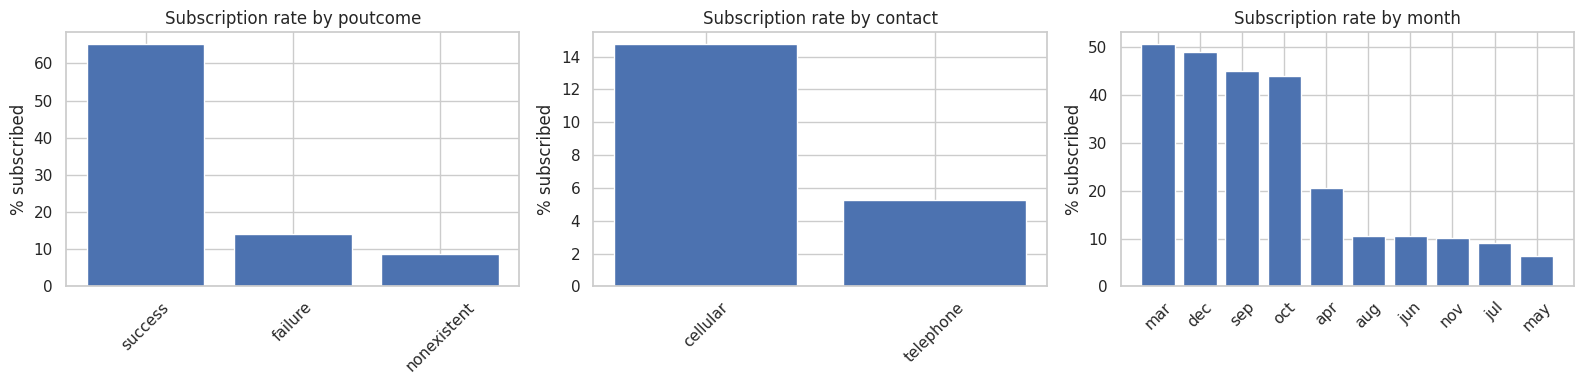

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["poutcome", "contact", "month"]):
    rate = (df.groupby(col)[TARGET].apply(lambda s: (s == "yes").mean()) * 100).sort_values(ascending=False)
    ax.bar(rate.index, rate.values, color="#4c72b0")
    ax.set_title(f"Subscription rate by {col}")
    ax.set_ylabel("% subscribed")
    ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()

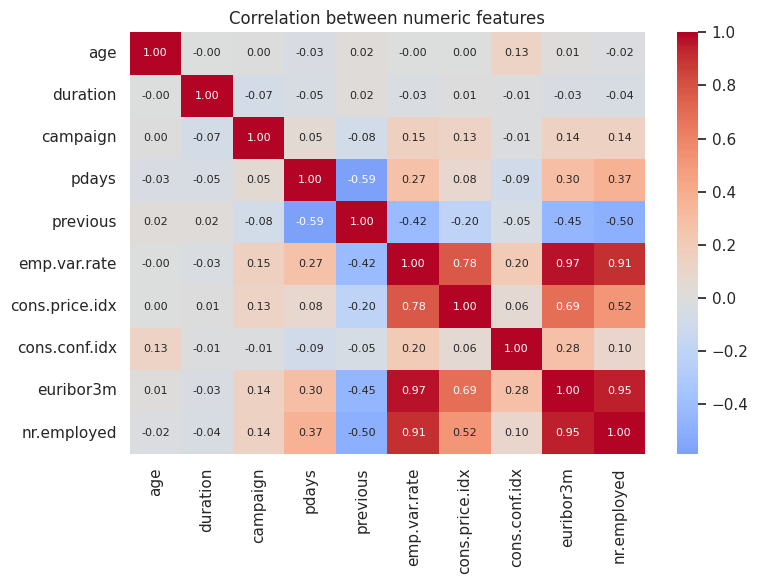

In [17]:
corr = df[numeric_cols].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, annot_kws={"size": 8})
ax.set_title("Correlation between numeric features")
fig.tight_layout()
plt.show()

The outcome of the previous campaign, the contact channel and the month all change the subscription
rate a lot. The macro-economic indicators (`emp.var.rate`, `euribor3m`, `nr.employed`) are strongly
correlated with each other, which matters for Naive Bayes because it assumes independent features.

## 2. Data preprocessing

Two feature decisions before splitting:

- **`duration` is dropped.** The call length is only known after the call ends, and by then the outcome
  is known too. The dataset documentation itself says it should be discarded for a realistic model, so
  keeping it would be target leakage.
- **`pdays` becomes `contacted_before`.** In 96% of rows `pdays` is 999, a placeholder meaning the client
  was never contacted before. Using 999 as a number would distort scaling, so I replace the column with a
  0/1 flag.

In [20]:
df["contacted_before"] = (df["pdays"] != 999).astype(int)
df = df.drop(columns=["duration", "pdays"])

X = df.drop(columns=TARGET)
y = (df[TARGET] == "yes").astype(int)

print("Feature matrix:", X.shape)
print("Features used :", X.columns.tolist())

Feature matrix: (41176, 19)
Features used : ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'contacted_before']


### 2.1 Train-test split (80:20, stratified, fixed seed)

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print(f"Train: {X_train.shape[0]} rows   Test: {X_test.shape[0]} rows")
print(f"Positive class share - full: {y.mean():.4f}  train: {y_train.mean():.4f}  test: {y_test.mean():.4f}")

# keep the untouched hold-out rows as the test data file for the repository
test_data = X_test.copy()
test_data[TARGET] = y_test.map({0: "no", 1: "yes"})
test_data.to_csv(ROOT / "test_data.csv", index=False)
print("Saved test_data.csv:", test_data.shape)

Train: 32940 rows   Test: 8236 rows
Positive class share - full: 0.1127  train: 0.1127  test: 0.1127
Saved test_data.csv: (8236, 20)


### 2.2 Imputation, encoding and scaling

| Feature group | Steps |
|---|---|
| Numeric | median imputation, then `StandardScaler` |
| Categorical (`job`, `marital`, `education`, `housing`, `loan`, `contact`, `month`, `day_of_week`, `poutcome`) | most-frequent imputation, then one-hot encoding |
| `default` | missing kept as its own `unknown` category, then one-hot encoding |

Scaling is needed for Logistic Regression and KNN (KNN is distance based) and does not hurt the tree models.
Everything is wrapped in a `ColumnTransformer` that goes inside each model's `Pipeline`, so the medians,
modes, category lists and scaling statistics are learned from the training rows only and then applied to
the test rows.

In [24]:
num_features = X.select_dtypes(include="number").columns.tolist()
cat_features = [c for c in X.columns if c not in num_features and c != "default"]

numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore")),
])
default_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="unknown")),
    ("encode", OneHotEncoder(handle_unknown="ignore")),
])


def make_preprocessor():
    # sparse_threshold=0 gives a dense array, which GaussianNB needs
    return ColumnTransformer([
        ("num", numeric_pipe, num_features),
        ("cat", categorical_pipe, cat_features),
        ("default", default_pipe, ["default"]),
    ], sparse_threshold=0)


check = make_preprocessor().fit(X_train)
print("Numeric features    :", len(num_features))
print("Categorical features:", len(cat_features) + 1)
print("Columns after encoding:", check.transform(X_train).shape[1])
print("Missing values left   :", int(np.isnan(check.transform(X_test)).sum()))

Numeric features    : 9
Categorical features: 10
Columns after encoding: 57
Missing values left   : 0


## 3. Models

All five models use the same split and the same preprocessing.

| Model | Configuration |
|---|---|
| Logistic Regression | `max_iter=1000`, `class_weight="balanced"` |
| Decision Tree | `max_depth=6`, `min_samples_leaf=50`, `class_weight="balanced"` |
| K-Nearest Neighbors | `n_neighbors=15` |
| Naive Bayes | `GaussianNB` with default settings |
| Random Forest | `n_estimators=300`, `max_depth=12`, `min_samples_leaf=5`, `class_weight="balanced"` |

The depth and leaf-size limits on the two tree models are there to stop them memorising the training set.
KNN and Gaussian Naive Bayes have no class-weight option, so they see the data with its natural imbalance.

In [26]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced",
                                              random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, class_weight="balanced",
                                            random_state=RANDOM_STATE),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=15),
    "Naive Bayes": GaussianNB(),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=12, min_samples_leaf=5,
                                            class_weight="balanced", n_jobs=-1,
                                            random_state=RANDOM_STATE),
}


def evaluate(y_true, y_pred, y_prob):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "AUC": roc_auc_score(y_true, y_prob),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "MCC": matthews_corrcoef(y_true, y_pred),
    }

In [27]:
fitted, test_pred, test_prob = {}, {}, {}
test_rows, train_rows = [], []

for name, estimator in models.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("model", estimator)])

    start = perf_counter()
    pipe.fit(X_train, y_train)
    fit_time = perf_counter() - start

    test_pred[name] = pipe.predict(X_test)
    test_prob[name] = pipe.predict_proba(X_test)[:, 1]
    fitted[name] = pipe

    test_rows.append({"Model": name, **evaluate(y_test, test_pred[name], test_prob[name])})
    train_rows.append({"Model": name,
                       **evaluate(y_train, pipe.predict(X_train), pipe.predict_proba(X_train)[:, 1])})
    print(f"{name:<20} trained in {fit_time:6.2f}s   test F1 = {test_rows[-1]['F1']:.4f}")

Logistic Regression  trained in   3.46s   test F1 = 0.4622
Decision Tree        trained in   0.48s   test F1 = 0.4842
K-Nearest Neighbors  trained in   0.22s   test F1 = 0.3665
Naive Bayes          trained in   0.24s   test F1 = 0.4244
Random Forest        trained in   4.50s   test F1 = 0.4994


## 4. Evaluation

Precision, Recall and F1 are reported for the positive class (`yes`), because finding the clients who
will subscribe is the point of the campaign.

In [29]:
results = pd.DataFrame(test_rows).set_index("Model").round(4)
results.to_csv(RESULTS_DIR / "model_comparison.csv")
results

,Accuracy,AUC,Precision,Recall,F1,MCC
Model,,,,,,
Logistic Regression,0.8307,0.8000,0.3600,0.6455,0.4622,0.3935
Decision Tree,0.8474,0.8006,0.3910,0.6358,0.4842,0.4169
K-Nearest Neighbors,0.8980,0.7728,0.6106,0.2619,0.3665,0.3548
Naive Bayes,0.8067,0.7780,0.3194,0.6325,0.4244,0.3504
Random Forest,0.8559,0.8136,0.4103,0.6379,0.4994,0.4338


In [30]:
# same metrics on the training rows, to see how much each model overfits
train_results = pd.DataFrame(train_rows).set_index("Model").round(4)
gap = pd.DataFrame({
    "Train F1": train_results["F1"], "Test F1": results["F1"],
    "Train AUC": train_results["AUC"], "Test AUC": results["AUC"],
})
gap["F1 gap"] = (gap["Train F1"] - gap["Test F1"]).round(4)
gap.to_csv(RESULTS_DIR / "train_vs_test.csv")
gap

,Train F1,Test F1,Train AUC,Test AUC,F1 gap
Model,,,,,
Logistic Regression,0.4531,0.4622,0.7953,0.8000,-0.0091
Decision Tree,0.4684,0.4842,0.7920,0.8006,-0.0158
K-Nearest Neighbors,0.4105,0.3665,0.8711,0.7728,0.0440
Naive Bayes,0.4103,0.4244,0.7689,0.7780,-0.0141
Random Forest,0.5099,0.4994,0.8777,0.8136,0.0105


### 4.1 Metrics in graph form

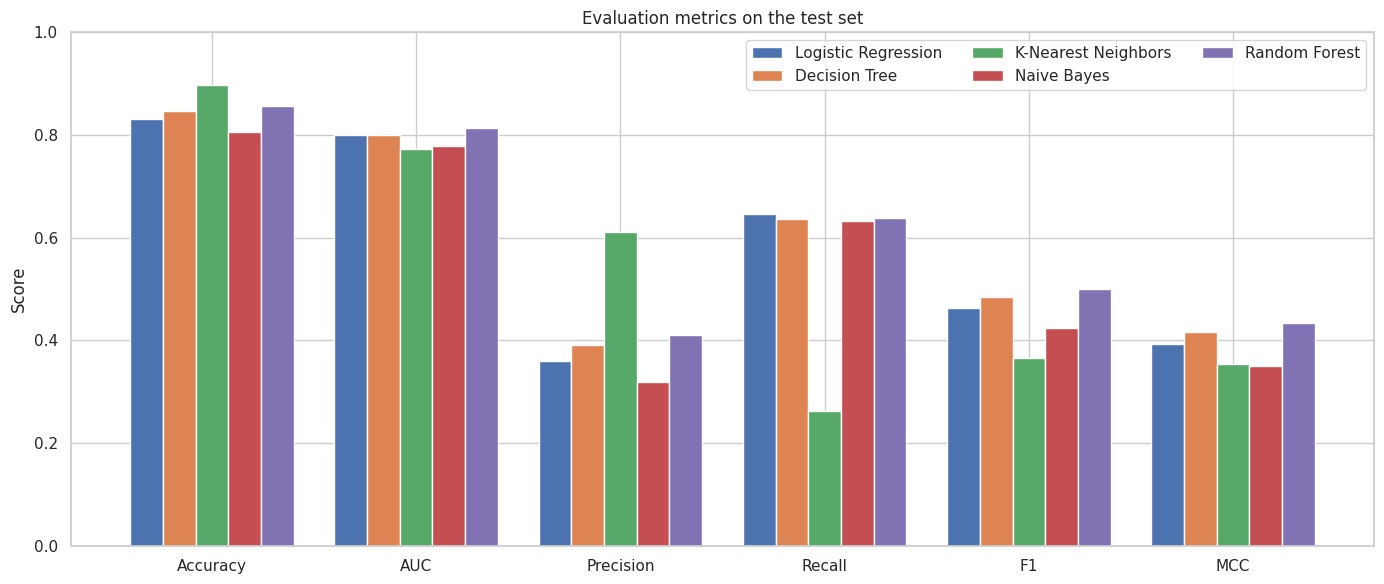

In [32]:
metric_names = results.columns.tolist()
x = np.arange(len(metric_names))
width = 0.16

fig, ax = plt.subplots(figsize=(14, 6))
for i, model_name in enumerate(results.index):
    ax.bar(x + (i - 2) * width, results.loc[model_name].values, width, label=model_name)
ax.set_xticks(x)
ax.set_xticklabels(metric_names)
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Evaluation metrics on the test set")
ax.legend(loc="upper right", ncol=3)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "metrics_comparison.png", dpi=150)
plt.show()

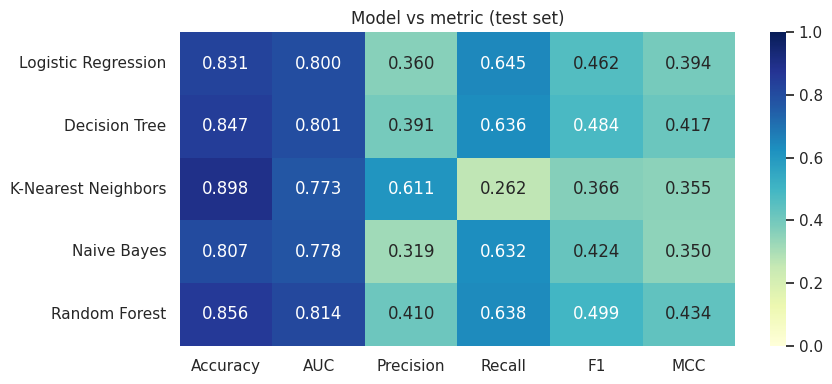

In [33]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(results, annot=True, fmt=".3f", cmap="YlGnBu", vmin=0, vmax=1, ax=ax)
ax.set_title("Model vs metric (test set)")
ax.set_ylabel("")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "metrics_heatmap.png", dpi=150)
plt.show()

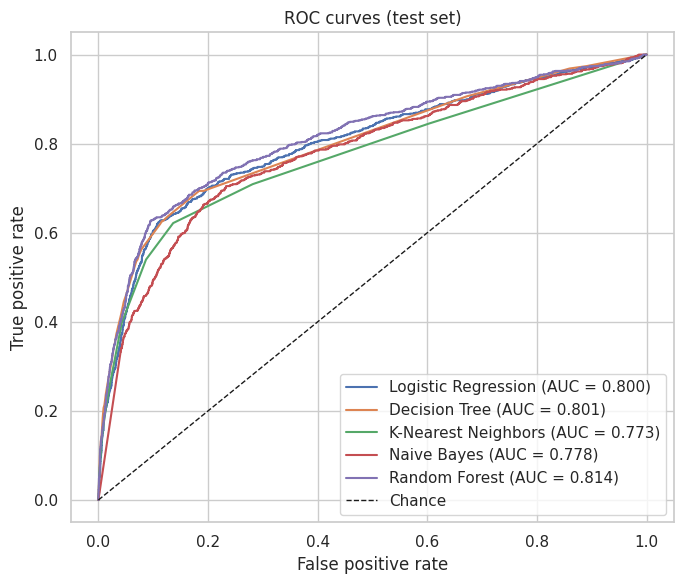

In [34]:
fig, ax = plt.subplots(figsize=(7, 6))
for name in models:
    fpr, tpr, _ = roc_curve(y_test, test_prob[name])
    ax.plot(fpr, tpr, label=f"{name} (AUC = {results.loc[name, 'AUC']:.3f})")
ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Chance")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curves (test set)")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "roc_curves.png", dpi=150)
plt.show()

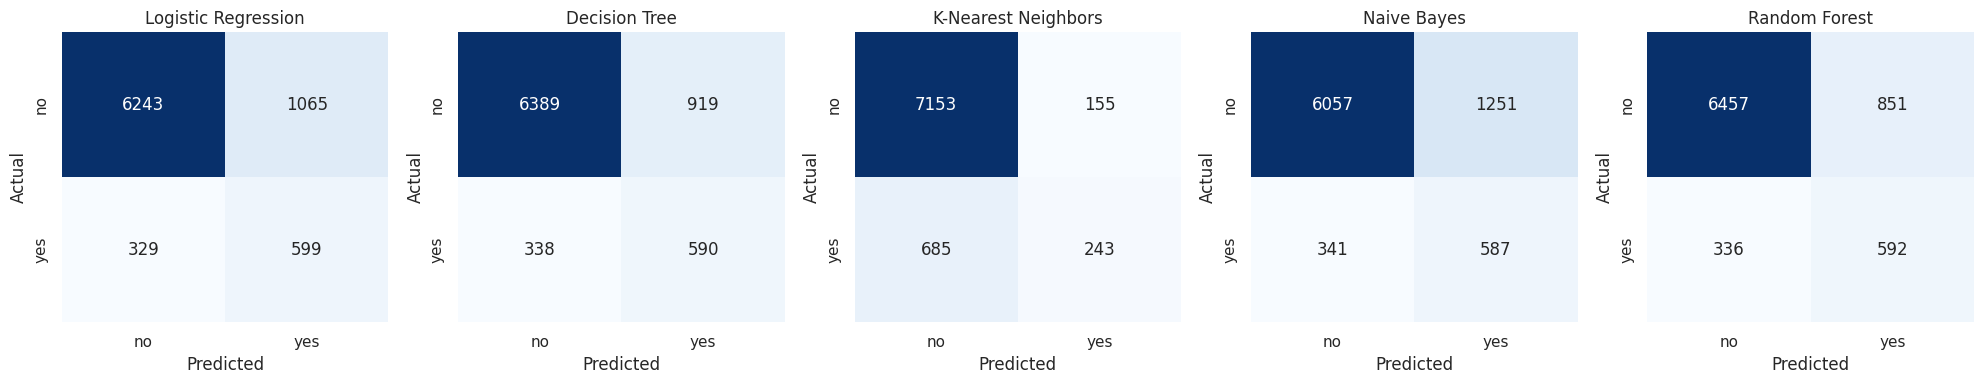

In [35]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, name in zip(axes, models):
    cm = confusion_matrix(y_test, test_pred[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["no", "yes"], yticklabels=["no", "yes"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "confusion_matrices.png", dpi=150)
plt.show()

## 5. Observations

| Model | Observation |
|---|---|
| Logistic Regression | Highest recall of the five (0.6455, 599 of the 928 subscribers in the test set), but precision is only 0.36 because 1,065 non-subscribers are flagged as well. Its AUC (0.8000) is almost the same as the Decision Tree, so a linear boundary already captures most of the signal. Train and test F1 are nearly equal (0.4531 vs 0.4622), so there is no overfitting. |
| Decision Tree | A little better than Logistic Regression on precision (0.3910), F1 (0.4842) and MCC (0.4169) with a similar AUC (0.8006). Limiting the depth to 6 and the leaf size to 50 keeps it from memorising the data: test F1 is not lower than train F1 (0.4842 vs 0.4684). |
| K-Nearest Neighbors | Best accuracy (0.8980) and best precision (0.61), but the worst recall (0.2619): it finds only 243 of 928 subscribers. Its accuracy is barely above the 88.73% obtained by always predicting "no", which shows how misleading accuracy is on this data. KNN has no class weighting, so the majority class dominates most neighbourhoods. It also has the lowest AUC (0.7728) and the biggest train-test gap (train AUC 0.8711 vs test 0.7728), so it overfits the most. |
| Naive Bayes | Recall (0.6325) is in line with the class-weighted models even without weighting, but it has the lowest precision (0.3194), accuracy (0.8067) and MCC (0.3504), with 1,251 false positives. The independence assumption does not hold here: the economic indicators (`emp.var.rate`, `euribor3m`, `nr.employed`) are strongly correlated, so the same evidence is counted several times and the probabilities become over-confident. |
| Random Forest | Best overall: highest AUC (0.8136), F1 (0.4994) and MCC (0.4338). Its recall (0.6379) is about the same as the other weighted models, and it has the fewest false positives of the four high-recall models (851, against 919 to 1,251), which is where the better precision (0.4103) comes from. Train AUC (0.8777) is higher than test AUC, so there is some overfitting, though less than KNN. |

**Overall**

- Random Forest is the model I would pick. Averaging 300 trees gives the best ranking of clients (AUC) and the best balance between precision and recall (F1, MCC), although its lead over the Decision Tree is small (F1 0.4994 against 0.4842).
- Accuracy is not a useful metric for this problem. KNN has the highest accuracy and the lowest F1, while the weighted models give up some accuracy to find more than 63% of the subscribers.
- All five AUC values fall between 0.77 and 0.81. Without the leaking `duration` feature, the remaining client and economic features only carry a moderate amount of signal, so the choice of model matters less than the choice of features.
- Which model is "best" also depends on cost. If a wasted call is cheap, the high-recall models (Logistic Regression, Random Forest) are preferable. If calls are expensive, KNN's high precision would be more attractive.